In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.home() / "UltraCNN"
DATASET_ROOT = PROJECT_ROOT / "data" / "kitti" / "stereo2012"

print("Project:", PROJECT_ROOT)
print("Dataset:", DATASET_ROOT)
print("Dataset directory exists:", DATASET_ROOT.exists())

Project: /home/ghost/UltraCNN
Dataset: /home/ghost/UltraCNN/data/kitti/stereo2012
Dataset directory exists: True


In [2]:
for path in sorted(DATASET_ROOT.rglob("*")):
    if path.is_dir():
        print(f"[DIR]  {path.relative_to(DATASET_ROOT)}")

[DIR]  data_stereo_flow
[DIR]  data_stereo_flow/testing
[DIR]  data_stereo_flow/testing/calib
[DIR]  data_stereo_flow/testing/colored_0
[DIR]  data_stereo_flow/testing/colored_1
[DIR]  data_stereo_flow/testing/image_0
[DIR]  data_stereo_flow/testing/image_1
[DIR]  data_stereo_flow/training
[DIR]  data_stereo_flow/training/calib
[DIR]  data_stereo_flow/training/colored_0
[DIR]  data_stereo_flow/training/colored_1
[DIR]  data_stereo_flow/training/disp_noc
[DIR]  data_stereo_flow/training/disp_occ
[DIR]  data_stereo_flow/training/disp_refl_noc
[DIR]  data_stereo_flow/training/disp_refl_occ
[DIR]  data_stereo_flow/training/flow_noc
[DIR]  data_stereo_flow/training/flow_occ
[DIR]  data_stereo_flow/training/image_0
[DIR]  data_stereo_flow/training/image_1
[DIR]  data_stereo_flow_calib
[DIR]  data_stereo_flow_calib/testing
[DIR]  data_stereo_flow_calib/testing/calib
[DIR]  data_stereo_flow_calib/training
[DIR]  data_stereo_flow_calib/training/calib


In [3]:
# Select the dataset split and image ID explicitly
SPLIT = "training"
IMAGE_ID = "000000"

if SPLIT not in ("training", "testing"):
    raise ValueError("SPLIT must be either 'training' or 'testing'.")

# Define the corresponding dataset directories
split_root = DATASET_ROOT / "data_stereo_flow" / SPLIT

left_dir = split_root / "colored_0"
right_dir = split_root / "colored_1"

# Calibration directory for the same dataset split
calib_root = (
    DATASET_ROOT / "data_stereo_flow_calib" / SPLIT / "calib"
)

print("Dataset split:", SPLIT)
print("Image ID:", IMAGE_ID)
print("Left image directory:", left_dir)
print("Right image directory:", right_dir)
print("Calibration directory:", calib_root)

Dataset split: training
Image ID: 000000
Left image directory: /home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow/training/colored_0
Right image directory: /home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow/training/colored_1
Calibration directory: /home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow_calib/training/calib


In [4]:
# Verify that the selected directories exist
if not left_dir.is_dir():
    raise FileNotFoundError(
        f"Left image directory not found: {left_dir}"
    )

if not right_dir.is_dir():
    raise FileNotFoundError(
        f"Right image directory not found: {right_dir}"
    )

# Construct the exact left and right image paths
left_path = left_dir / f"{IMAGE_ID}_10.png"
right_path = right_dir / left_path.name

# Verify that both images exist
if not left_path.is_file():
    raise FileNotFoundError(
        f"Left image not found: {left_path}"
    )

if not right_path.is_file():
    raise FileNotFoundError(
        f"Right image not found: {right_path}"
    )

# Load both images
left_image = cv2.imread(str(left_path))
right_image = cv2.imread(str(right_path))

# Verify that OpenCV loaded both images successfully
if left_image is None or right_image is None:
    raise RuntimeError("Failed to read one or both images.")

print("Dataset split:", SPLIT)
print("Left image:", left_path)
print("Right image:", right_path)
print("Left dimensions:", left_image.shape)
print("Right dimensions:", right_image.shape)

Dataset split: training
Left image: /home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow/training/colored_0/000000_10.png
Right image: /home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow/training/colored_1/000000_10.png
Left dimensions: (370, 1226, 3)
Right dimensions: (370, 1226, 3)


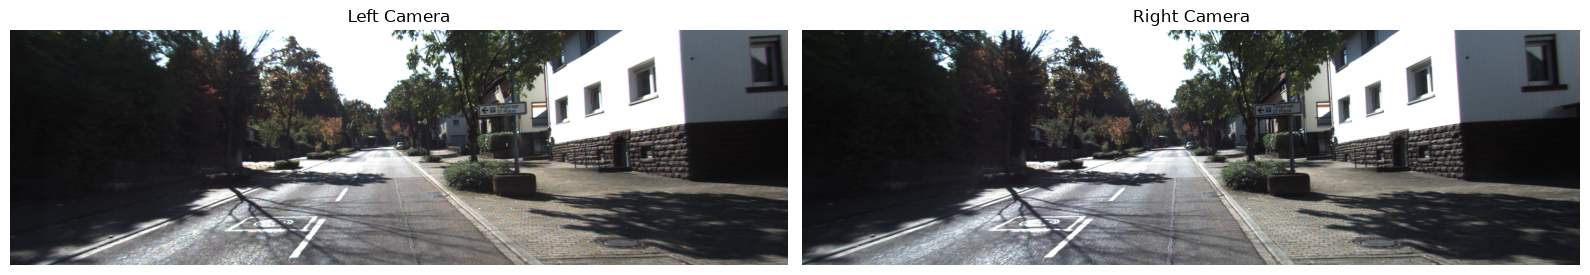

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(cv2.cvtColor(left_image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Left Camera")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(right_image, cv2.COLOR_BGR2RGB))
axes[1].set_title("Right Camera")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [6]:
assert left_image.shape == right_image.shape, (
    "Left and right image dimensions do not match."
)

height, width = left_image.shape[:2]

print(f"Image width:  {width} pixels")
print(f"Image height: {height} pixels")
print(f"Image size:   {width * height:,} pixels")

Image width:  1226 pixels
Image height: 370 pixels
Image size:   453,620 pixels


Left image shape: (370, 1226, 3)
Right image shape: (370, 1226, 3)


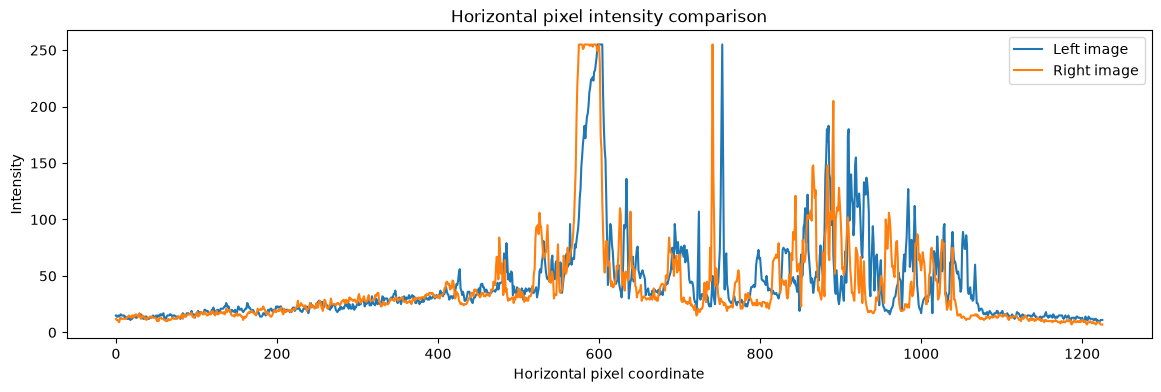

In [7]:
print("Left image shape:", left_image.shape)
print("Right image shape:", right_image.shape)

# Display a horizontal slice from both images
row = left_image.shape[0] // 2

plt.figure(figsize=(14, 4))
plt.plot(left_image[row, :, 0], label="Left image")
plt.plot(right_image[row, :, 0], label="Right image")
plt.title("Horizontal pixel intensity comparison")
plt.xlabel("Horizontal pixel coordinate")
plt.ylabel("Intensity")
plt.legend()
plt.show()

In [8]:
# Find calibration files within the selected dataset split
calib_files = sorted(calib_root.glob("*.txt"))

print("Dataset split:", SPLIT)
print("Number of calibration files:", len(calib_files))
print("Calibration directory:", calib_root)

for path in calib_files[:10]:
    print(path.name)

Dataset split: training
Number of calibration files: 194
Calibration directory: /home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow_calib/training/calib
000000.txt
000001.txt
000002.txt
000003.txt
000004.txt
000005.txt
000006.txt
000007.txt
000008.txt
000009.txt


In [9]:
import numpy as np

# Construct the calibration filename from the selected image ID
calib_path = calib_root / f"{IMAGE_ID}.txt"

# Verify that the matching calibration file exists
if not calib_path.is_file():
    raise FileNotFoundError(
        f"Matching calibration file not found: {calib_path}"
    )

# Parse the calibration file
calibration = {}

with open(calib_path, "r") as file:
    for line in file:
        if ":" not in line:
            continue

        key, values = line.split(":", 1)

        try:
            calibration[key.strip()] = np.array(
                [float(x) for x in values.split()]
            )
        except ValueError:
            continue

print("Dataset split:", SPLIT)
print("Image ID:", IMAGE_ID)
print("Calibration file:", calib_path)
print("Available calibration keys:", list(calibration.keys()))

Dataset split: training
Image ID: 000000
Calibration file: /home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow_calib/training/calib/000000.txt
Available calibration keys: ['P0', 'P1', 'P2', 'P3']


In [10]:
for key in ["P2", "P3"]:
    if key in calibration:
        print(f"\n{key}:")
        print(calibration[key].reshape(3, 4))


P2:
[[7.070912e+02 0.000000e+00 6.018873e+02 4.688783e+01]
 [0.000000e+00 7.070912e+02 1.831104e+02 1.178601e-01]
 [0.000000e+00 0.000000e+00 1.000000e+00 6.203223e-03]]

P3:
[[ 7.070912e+02  0.000000e+00  6.018873e+02 -3.334597e+02]
 [ 0.000000e+00  7.070912e+02  1.831104e+02  1.930130e+00]
 [ 0.000000e+00  0.000000e+00  1.000000e+00  3.318498e-03]]


In [11]:
if "P2" not in calibration or "P3" not in calibration:
    raise KeyError(
        "P2/P3 were not found. Inspect the available calibration keys "
        "and we'll adapt the parser to your calibration format."
    )

P2 = calibration["P2"].reshape(3, 4)
P3 = calibration["P3"].reshape(3, 4)

focal_length = P2[0, 0]

left_camera_offset = P2[0, 3] / P2[0, 0]
right_camera_offset = P3[0, 3] / P3[0, 0]

baseline = abs(right_camera_offset - left_camera_offset)

print(f"Focal length: {focal_length:.3f} pixels")
print(f"Stereo baseline: {baseline:.4f} metres")

Focal length: 707.091 pixels
Stereo baseline: 0.5379 metres


In [12]:
# Convert stereo images to grayscale
left_gray = cv2.cvtColor(left_image, cv2.COLOR_BGR2GRAY)
right_gray = cv2.cvtColor(right_image, cv2.COLOR_BGR2GRAY)

# StereoSGBM parameters
window_size = 5
min_disparity = 0
num_disparities = 128

stereo = cv2.StereoSGBM_create(
    minDisparity=min_disparity,
    numDisparities=num_disparities,
    blockSize=window_size,
    P1=8 * window_size**2,
    P2=32 * window_size**2,
    disp12MaxDiff=1,
    uniquenessRatio=10,
    speckleWindowSize=100,
    speckleRange=2,
    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
)

print("StereoSGBM initialized.")
print("Image dimensions:", left_gray.shape)

StereoSGBM initialized.
Image dimensions: (370, 1226)


In [13]:
disparity_raw = stereo.compute(left_gray, right_gray)

# OpenCV StereoSGBM stores disparity with a scale factor of 16.
disparity = disparity_raw.astype(np.float32) / 16.0

valid_disparity = disparity > min_disparity

print("Disparity shape:", disparity.shape)
print("Valid disparity pixels:", valid_disparity.sum())
print(
    "Percentage of valid pixels:",
    f"{100 * valid_disparity.mean():.2f}%"
)

if valid_disparity.any():
    print(
        "Disparity range:",
        float(disparity[valid_disparity].min()),
        "to",
        float(disparity[valid_disparity].max()),
        "pixels"
    )

Disparity shape: (370, 1226)
Valid disparity pixels: 372268
Percentage of valid pixels: 82.07%
Disparity range: 1.0625 to 72.375 pixels


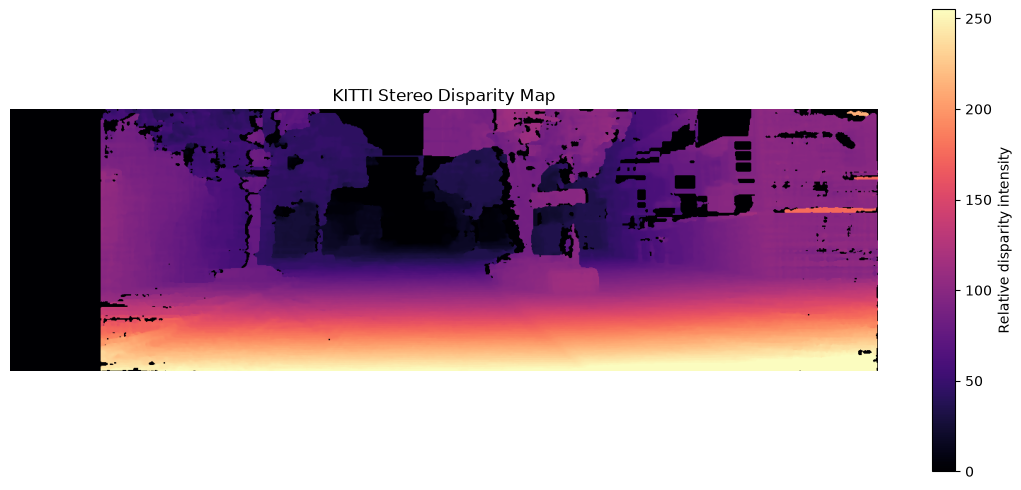

In [14]:
disparity_visual = np.zeros_like(disparity, dtype=np.uint8)

if valid_disparity.any():
    values = disparity[valid_disparity]

    low, high = np.percentile(values, [2, 98])

    if high > low:
        normalized = np.clip(
            (disparity - low) / (high - low),
            0,
            1
        )

        disparity_visual = (normalized * 255).astype(np.uint8)

        disparity_visual[~valid_disparity] = 0

plt.figure(figsize=(14, 6))

plt.imshow(disparity_visual, cmap="magma")
plt.title("KITTI Stereo Disparity Map")
plt.colorbar(label="Relative disparity intensity")
plt.axis("off")

plt.show()

In [15]:
depth = np.full(disparity.shape, np.nan, dtype=np.float32)

valid_depth = (
    np.isfinite(disparity)
    & (disparity > 0)
)

depth[valid_depth] = (
    focal_length * baseline / disparity[valid_depth]
)

print("Valid depth pixels:", np.isfinite(depth).sum())

if np.isfinite(depth).any():
    print(
        "Depth percentiles (metres):",
        np.nanpercentile(depth, [5, 25, 50, 75, 95])
    )

Valid depth pixels: 372268
Depth percentiles (metres): [ 6.43974638 10.04217911 14.48942947 21.13041878 47.9178009 ]


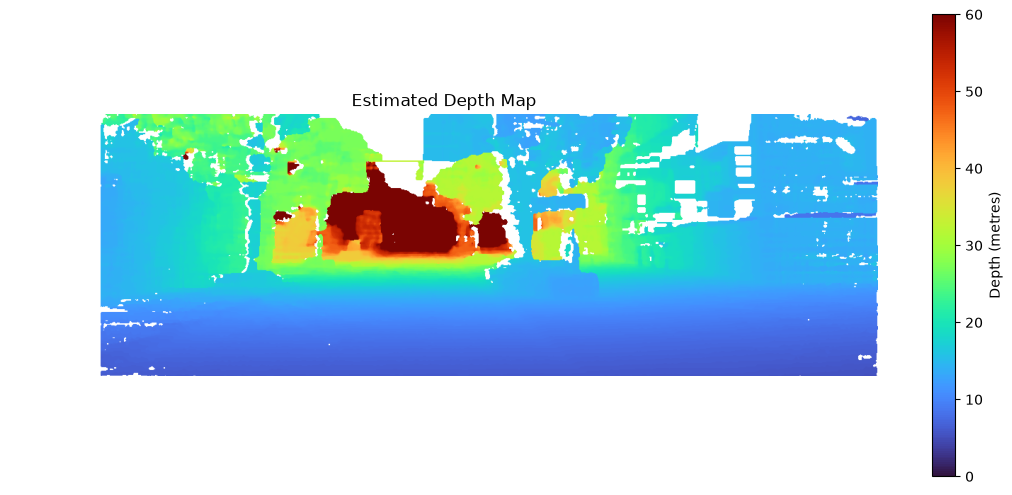

In [16]:
valid_depth = np.isfinite(depth) & (depth > 0)

depth_display = np.ma.masked_invalid(depth)

plt.figure(figsize=(14, 6))

plt.imshow(depth_display, cmap="turbo", vmin=0, vmax=60)
plt.title("Estimated Depth Map")
plt.colorbar(label="Depth (metres)")
plt.axis("off")

plt.show()

In [17]:
# Locate the ground-truth disparity image for our selected frame
gt_disparity_dir = (
    DATASET_ROOT
    / "data_stereo_flow"
    / SPLIT
    / "disp_occ"
)

gt_disparity_path = gt_disparity_dir / f"{IMAGE_ID}_10.png"

if not gt_disparity_path.is_file():
    raise FileNotFoundError(
        f"Ground-truth disparity not found: {gt_disparity_path}"
    )

# Read the original 16-bit disparity image
gt_disparity_raw = cv2.imread(
    str(gt_disparity_path),
    cv2.IMREAD_UNCHANGED
)

if gt_disparity_raw is None:
    raise RuntimeError("Failed to load ground-truth disparity.")

print("Ground-truth path:", gt_disparity_path)
print("Ground-truth dtype:", gt_disparity_raw.dtype)
print("Ground-truth shape:", gt_disparity_raw.shape)
print("Ground-truth raw range:", gt_disparity_raw.min(),
      "to", gt_disparity_raw.max())

Ground-truth path: /home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow/training/disp_occ/000000_10.png
Ground-truth dtype: uint16
Ground-truth shape: (370, 1226)
Ground-truth raw range: 0 to 17873


In [18]:
gt_disparity = gt_disparity_raw.astype(np.float32) / 256.0

# Zero represents invalid ground-truth disparity
valid_gt = (
    np.isfinite(gt_disparity)
    & (gt_disparity > 0)
)

print("Valid ground-truth pixels:", int(valid_gt.sum()))
print(
    "Valid ground-truth percentage:",
    f"{100 * valid_gt.mean():.2f}%"
)

if valid_gt.any():
    print(
        "Ground-truth disparity range:",
        float(gt_disparity[valid_gt].min()),
        "to",
        float(gt_disparity[valid_gt].max()),
        "pixels"
    )

Valid ground-truth pixels: 162583
Valid ground-truth percentage: 35.84%
Ground-truth disparity range: 4.40234375 to 69.81640625 pixels


In [19]:
if disparity.shape != gt_disparity.shape:
    raise ValueError(
        f"Shape mismatch: predicted {disparity.shape}, "
        f"ground truth {gt_disparity.shape}"
    )

valid_pred = np.isfinite(disparity) & (disparity > 0)

# Evaluate only pixels with valid ground truth and predictions
evaluation_mask = valid_gt & valid_pred

if not evaluation_mask.any():
    raise ValueError("No overlapping valid disparity pixels.")

pred_values = disparity[evaluation_mask]
gt_values = gt_disparity[evaluation_mask]

errors = pred_values - gt_values
absolute_errors = np.abs(errors)

mae = float(np.mean(absolute_errors))
rmse = float(np.sqrt(np.mean(errors ** 2)))

# Percentage of evaluated pixels with absolute error > 3 pixels
bad_3px = float(np.mean(absolute_errors > 3.0) * 100)

# KITTI-style D1 criterion:
# absolute error > 3 pixels AND relative error > 5%
relative_errors = absolute_errors / gt_values

d1_mask = (
    (absolute_errors > 3.0)
    & (relative_errors > 0.05)
)

d1_error = float(np.mean(d1_mask) * 100)

print("=== STEREO DISPARITY EVALUATION ===")
print(f"Evaluated pixels: {int(evaluation_mask.sum()):,}")
print(f"Coverage of valid ground truth: "
      f"{100 * evaluation_mask.sum() / valid_gt.sum():.2f}%")
print(f"Disparity MAE: {mae:.3f} pixels")
print(f"Disparity RMSE: {rmse:.3f} pixels")
print(f"Pixels with error > 3 px: {bad_3px:.2f}%")
print(f"D1 error rate: {d1_error:.2f}%")

=== STEREO DISPARITY EVALUATION ===
Evaluated pixels: 145,412
Coverage of valid ground truth: 89.44%
Disparity MAE: 0.485 pixels
Disparity RMSE: 1.136 pixels
Pixels with error > 3 px: 0.84%
D1 error rate: 0.84%


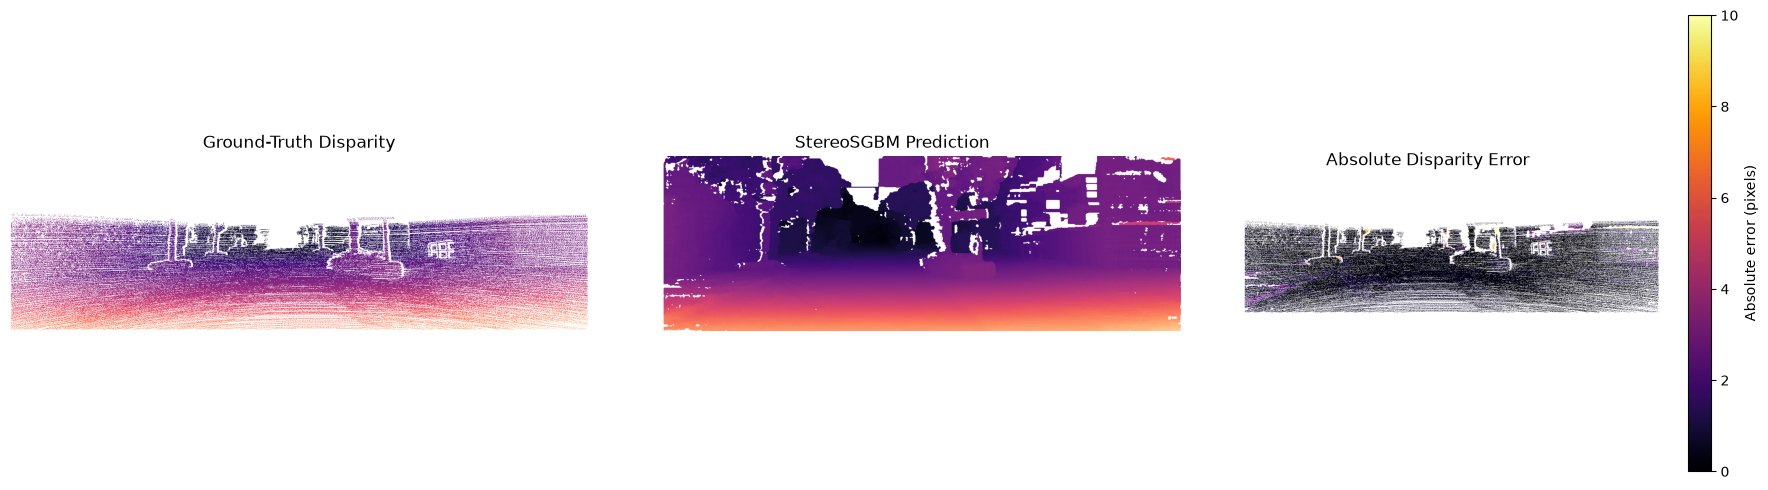

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(
    np.ma.masked_where(~valid_gt, gt_disparity),
    cmap="magma",
    vmin=0,
    vmax=80
)
axes[0].set_title("Ground-Truth Disparity")

axes[1].imshow(
    np.ma.masked_where(~valid_pred, disparity),
    cmap="magma",
    vmin=0,
    vmax=80
)
axes[1].set_title("StereoSGBM Prediction")

error_map = np.full(disparity.shape, np.nan, dtype=np.float32)
error_map[evaluation_mask] = np.abs(
    disparity[evaluation_mask] - gt_disparity[evaluation_mask]
)

im = axes[2].imshow(
    error_map,
    cmap="inferno",
    vmin=0,
    vmax=10
)
axes[2].set_title("Absolute Disparity Error")

for ax in axes:
    ax.axis("off")

fig.colorbar(im, ax=axes[2], label="Absolute error (pixels)")
plt.tight_layout()
plt.show()

In [21]:
# Evaluate only pixels with valid ground truth and valid predictions

valid_gt = np.isfinite(gt_disparity) & (gt_disparity > 0)
valid_pred = np.isfinite(disparity) & (disparity > 0)

evaluation_mask = valid_gt & valid_pred

gt_count = int(valid_gt.sum())
pred_count = int(valid_pred.sum())
overlap_count = int(evaluation_mask.sum())

print(f"Valid ground-truth pixels: {gt_count:,}")
print(f"Valid predicted pixels:    {pred_count:,}")
print(f"Overlapping valid pixels:  {overlap_count:,}")
print(f"Ground-truth coverage:     {100 * gt_count / gt_disparity.size:.2f}%")
print(f"Prediction coverage:       {100 * pred_count / disparity.size:.2f}%")
print(f"Evaluation coverage:       {100 * overlap_count / gt_count:.2f}%")

if overlap_count == 0:
    raise ValueError("No overlapping valid pixels.")

errors = disparity[evaluation_mask] - gt_disparity[evaluation_mask]
absolute_errors = np.abs(errors)

print(f"\nDisparity MAE:  {absolute_errors.mean():.3f} pixels")
print(f"Disparity RMSE: {np.sqrt(np.mean(errors**2)):.3f} pixels")
print(f"Bad-3 rate:     {100 * np.mean(absolute_errors > 3):.2f}%")

Valid ground-truth pixels: 162,583
Valid predicted pixels:    372,268
Overlapping valid pixels:  145,412
Ground-truth coverage:     35.84%
Prediction coverage:       82.07%
Evaluation coverage:       89.44%

Disparity MAE:  0.485 pixels
Disparity RMSE: 1.136 pixels
Bad-3 rate:     0.84%


In [22]:
# Convert disparity into depth using the calibrated stereo geometry

focal_baseline = focal_length * baseline

predicted_depth = np.full(disparity.shape, np.nan, dtype=np.float32)
ground_truth_depth = np.full(gt_disparity.shape, np.nan, dtype=np.float32)

# Use only positive, valid disparity values
valid_pred = np.isfinite(disparity) & (disparity > 0)
valid_gt = np.isfinite(gt_disparity) & (gt_disparity > 0)

predicted_depth[valid_pred] = (
    focal_baseline / disparity[valid_pred]
)

ground_truth_depth[valid_gt] = (
    focal_baseline / gt_disparity[valid_gt]
)

print(f"Focal length: {focal_length:.3f} pixels")
print(f"Baseline: {baseline:.4f} metres")
print(f"Focal length × baseline: {focal_baseline:.3f}")

Focal length: 707.091 pixels
Baseline: 0.5379 metres
Focal length × baseline: 380.348


In [23]:
# Evaluate depth only where both disparity maps are valid.
# Restrict evaluation to depths up to 80 metres.

evaluation_mask = (
    valid_gt
    & valid_pred
    & np.isfinite(ground_truth_depth)
    & np.isfinite(predicted_depth)
    & (ground_truth_depth > 0)
    & (ground_truth_depth <= 80)
    & (predicted_depth > 0)
)

gt_depth_values = ground_truth_depth[evaluation_mask]
pred_depth_values = predicted_depth[evaluation_mask]

depth_errors = pred_depth_values - gt_depth_values
absolute_depth_errors = np.abs(depth_errors)

depth_mae = float(np.mean(absolute_depth_errors))
depth_rmse = float(np.sqrt(np.mean(depth_errors ** 2)))
depth_median_ae = float(np.median(absolute_depth_errors))

print("=== DEPTH ESTIMATION EVALUATION ===")
print(f"Evaluated pixels: {len(gt_depth_values):,}")
print(f"Depth MAE:        {depth_mae:.3f} metres")
print(f"Depth RMSE:       {depth_rmse:.3f} metres")
print(f"Median absolute error: {depth_median_ae:.3f} metres")

=== DEPTH ESTIMATION EVALUATION ===
Evaluated pixels: 145,305
Depth MAE:        0.392 metres
Depth RMSE:       1.798 metres
Median absolute error: 0.125 metres


In [24]:
import pandas as pd

distance_bins = [
    (0, 10),
    (10, 20),
    (20, 40),
    (40, 80),
]

depth_results = []

for lower, upper in distance_bins:
    mask = (
        evaluation_mask
        & (ground_truth_depth >= lower)
        & (ground_truth_depth < upper)
    )

    count = int(mask.sum())

    if count == 0:
        continue

    errors = predicted_depth[mask] - ground_truth_depth[mask]

    depth_results.append({
        "Distance range (m)": f"{lower}-{upper}",
        "Pixels": count,
        "MAE (m)": np.mean(np.abs(errors)),
        "RMSE (m)": np.sqrt(np.mean(errors ** 2)),
    })

depth_results_df = pd.DataFrame(depth_results)

display(depth_results_df.round(3))

,Distance range (m),Pixels,MAE (m),RMSE (m)
0,0-10,46324,0.081,0.114
1,10-20,74344,0.291,1.147
2,20-40,19496,0.918,3.268
3,40-80,5141,2.661,5.627
